# UrbanFlow AI — Notebook 11: Explainability Analysis

## Objective
Inspect how the trained Multi-Scale STGCN responds to input traffic observations and graph structure using simple, model-agnostic perturbation analyses.

This notebook provides:
1. **Temporal occlusion:** measure prediction changes when one historical input step is replaced with a reference value.
2. **Sensor occlusion:** measure prediction changes when one sensor's history is replaced with a reference value.
3. **Input-gradient summary (optional):** estimate local sensitivity using gradients if the model is differentiable with respect to its input.

These are sensitivity analyses, not causal explanations. A large score means the model's predictions changed substantially under the chosen perturbation; it does not prove a sensor or time step caused future traffic.

**This is a reconstructed notebook**, not the original missing file. Run it with the same checkpoint, architecture, preprocessing, and scaler as the model you want to explain.


In [68]:
from pathlib import Path
import json, pickle, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
INPUT_STEPS = 12
OUTPUT_STEPS = 3
NUM_NODES = 207
HIDDEN_CHANNELS = 32
DROPOUT = 0.2
BATCH_SIZE = 64

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Drive mount skipped (not running in Google Colab).")

PROJECT_ROOT = Path("/content/drive/MyDrive/urbanAi")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "METR-LA"
CHECKPOINT_PATH = Path("/content/experiments/multiscale_ablation/kernels_3_5/best_model.pt")
OUTPUT_DIR = Path("/content/experiments/explainability")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert (PROCESSED_DIR / "test.npz").exists(), f"Missing test split: {PROCESSED_DIR / 'test.npz'}"
assert (PROCESSED_DIR / "scaler.npz").exists(), f"Missing scaler: {PROCESSED_DIR / 'scaler.npz'}"
assert (PROCESSED_DIR / "adj_METR-LA.pkl").exists(), f"Missing adjacency: {PROCESSED_DIR / 'adj_METR-LA.pkl'}"
assert CHECKPOINT_PATH.exists(), f"Missing checkpoint: {CHECKPOINT_PATH}"


Device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load data, scaler, and adjacency

In [69]:
with np.load(PROCESSED_DIR / "test.npz") as z:
    print("Test keys:", z.files)
    X_test = z["X"].astype(np.float32)
    Y_test = z["Y"].astype(np.float32)

assert X_test.ndim == 4 and X_test.shape[1:] == (INPUT_STEPS, NUM_NODES, 1), X_test.shape
assert Y_test.ndim == 4 and Y_test.shape[1:] == (OUTPUT_STEPS, NUM_NODES, 1), Y_test.shape

with np.load(PROCESSED_DIR / "scaler.npz") as s:
    print("Scaler keys:", s.files)
    scaler_mean = s["mean"].astype(np.float32).reshape(1, 1, NUM_NODES, 1)
    scaler_std = s["std"].astype(np.float32).reshape(1, 1, NUM_NODES, 1)
assert np.all(scaler_std > 0)

def inverse_scale(x):
    return x * scaler_std + scaler_mean

with open(PROCESSED_DIR / "adj_METR-LA.pkl", "rb") as f:
    adj_raw = pickle.load(f, encoding="latin1")
A_np = np.asarray(adj_raw[-1] if isinstance(adj_raw, (tuple, list)) else adj_raw, dtype=np.float32)
assert A_np.shape == (NUM_NODES, NUM_NODES), A_np.shape
row_sum = A_np.sum(axis=1, keepdims=True)
if np.any(row_sum <= 0):
    raise ValueError("Adjacency contains zero-degree rows.")
A_np = A_np / row_sum
A = torch.tensor(A_np, dtype=torch.float32, device=DEVICE)

print("X_test:", X_test.shape, "Y_test:", Y_test.shape, "A:", A.shape)


Test keys: ['X', 'Y']
Scaler keys: ['mean', 'std']
X_test: (6841, 12, 207, 1) Y_test: (6841, 3, 207, 1) A: torch.Size([207, 207])


## 2. Define the model

The model implementation below is copied from the user's uploaded Notebook 06, including its temporal branch layout, fusion layers, graph convolution, temporal head, and output head. The checkpoint is loaded with `strict=True`; do not disable strict loading to force an incompatible checkpoint.


In [70]:
# Exact MultiScaleSTGCN architecture recovered from Notebook 06 (cell 16).
# Keep this architecture unchanged when loading the matching checkpoint.

class MultiScaleTemporalConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernels=(3, 5), dropout=0.2):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=(1, k),
                padding=(0, k // 2)
            )
            for k in kernels
        ])
        self.fusion = nn.Conv2d(
            out_channels * len(kernels), out_channels, kernel_size=1
        )
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Input/output: (B, T, N, C); convolution operates on time.
        x = x.permute(0, 3, 2, 1)  # B, C, N, T
        x = torch.cat([branch(x) for branch in self.branches], dim=1)
        x = self.dropout(self.activation(self.fusion(x)))
        return x.permute(0, 3, 2, 1)  # B, T, N, C


class GraphConvolution(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.linear = nn.Linear(in_channels, out_channels)

    def forward(self, x, adjacency):
        return self.linear(torch.einsum("nm,btmc->btnc", adjacency, x))


class MultiScaleSTGCNBlock(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernels=(3, 5), dropout=0.2):
        super().__init__()
        self.temporal1 = MultiScaleTemporalConv(
            in_channels, hidden_channels, kernels, dropout
        )
        self.graph = GraphConvolution(hidden_channels, hidden_channels)
        self.temporal2 = MultiScaleTemporalConv(
            hidden_channels, hidden_channels, kernels, dropout
        )
        self.activation = nn.ReLU()

    def forward(self, x, adjacency):
        x = self.temporal1(x)
        x = self.activation(self.graph(x, adjacency))
        return self.temporal2(x)


class MultiScaleSTGCN(nn.Module):
    def __init__(
        self, input_steps=12, output_steps=3, input_channels=1,
        hidden_channels=32, kernels=(3, 5), dropout=0.2
    ):
        super().__init__()
        self.block1 = MultiScaleSTGCNBlock(
            input_channels, hidden_channels, kernels, dropout
        )
        self.block2 = MultiScaleSTGCNBlock(
            hidden_channels, hidden_channels, kernels, dropout
        )
        self.temporal_head = nn.Linear(input_steps, output_steps)
        self.output_head = nn.Linear(hidden_channels, 1)

    def forward(self, x, adjacency):
        x = self.block1(x, adjacency)
        x = self.block2(x, adjacency)
        x = x.permute(0, 2, 3, 1)   # B, N, C, T
        x = self.temporal_head(x)   # B, N, C, H
        x = x.permute(0, 3, 1, 2)  # B, H, N, C
        return self.output_head(x)


model = MultiScaleSTGCN(
    input_steps=INPUT_STEPS,
    output_steps=OUTPUT_STEPS,
    input_channels=1,
    hidden_channels=HIDDEN_CHANNELS,
    kernels=(3, 5),
    dropout=DROPOUT,
).to(DEVICE)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Strict loading is intentional: all checkpoint weights must match.
model.load_state_dict(state_dict, strict=True)
model.eval()
print("Exact Notebook 06 architecture loaded successfully:", CHECKPOINT_PATH)


Exact Notebook 06 architecture loaded successfully: /content/experiments/multiscale_ablation/kernels_3_5/best_model.pt


## 3. Baseline predictions and reference values

Inputs are standardized. For occlusion, each replaced input value is set to zero in standardized space, which corresponds approximately to the training mean for that sensor. The test targets are not modified.


In [71]:
@torch.no_grad()
def predict(x_np, batch_size=BATCH_SIZE):
    model.eval()
    preds = []
    for start in range(0, len(x_np), batch_size):
        xb = torch.tensor(x_np[start:start+batch_size], dtype=torch.float32, device=DEVICE)
        pred = model(xb, A)
        preds.append(pred.cpu().numpy())
    return np.concatenate(preds, axis=0)

# Use a reproducible subset for computationally manageable perturbation analysis.
rng = np.random.default_rng(SEED)
N_EXPLAIN = min(512, len(X_test))
sample_indices = np.sort(rng.choice(len(X_test), size=N_EXPLAIN, replace=False))
X_explain = X_test[sample_indices].copy()
Y_explain = Y_test[sample_indices].copy()

baseline_pred_scaled = predict(X_explain)
baseline_pred_original = inverse_scale(baseline_pred_scaled)
Y_explain_original = inverse_scale(Y_explain)
print("Explained samples:", len(X_explain))
print("Prediction shape:", baseline_pred_original.shape)


Explained samples: 512
Prediction shape: (512, 3, 207, 1)


## 4. Temporal occlusion importance

,input_step_index,minutes_before_forecast,mean_absolute_prediction_change,p95_absolute_prediction_change
0,0,55,0.131674,0.652037
1,1,50,0.166075,0.648011
2,2,45,0.259730,0.906676
3,3,40,0.441637,1.670089
4,4,35,0.601087,2.195524
5,5,30,0.740431,2.604170
6,6,25,1.138714,5.227455
7,7,20,1.706397,8.980957
8,8,15,2.446816,14.452316
9,9,10,3.112062,13.798149


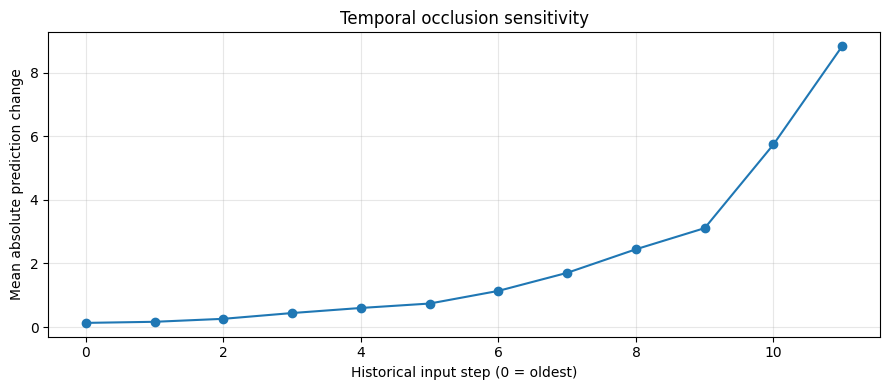

In [72]:
# Replace one entire historical time step with standardized zero for all sensors.
temporal_rows = []
for t in range(INPUT_STEPS):
    X_occ = X_explain.copy()
    X_occ[:, t, :, :] = 0.0
    pred_occ = inverse_scale(predict(X_occ))
    delta = np.abs(pred_occ - baseline_pred_original)
    temporal_rows.append({
        "input_step_index": t,
        "minutes_before_forecast": (INPUT_STEPS - 1 - t) * 5,
        "mean_absolute_prediction_change": float(delta.mean()),
        "p95_absolute_prediction_change": float(np.percentile(delta, 95)),
    })

temporal_df = pd.DataFrame(temporal_rows)
display(temporal_df.round(6))
temporal_df.to_csv(OUTPUT_DIR / "temporal_occlusion_importance.csv", index=False)

plt.figure(figsize=(9, 4))
plt.plot(temporal_df["input_step_index"], temporal_df["mean_absolute_prediction_change"], marker="o")
plt.xlabel("Historical input step (0 = oldest)")
plt.ylabel("Mean absolute prediction change")
plt.title("Temporal occlusion sensitivity")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Sensor occlusion importance

,sensor_index,mean_absolute_prediction_change,p95_absolute_prediction_change
82,82,0.233101,1.317758
76,76,0.213465,0.840091
60,60,0.209338,0.887546
81,81,0.199751,1.028663
43,43,0.187908,1.027087
72,72,0.177771,0.893138
146,146,0.176977,1.059700
181,181,0.175758,0.012699
63,63,0.175665,0.752411
9,9,0.168595,0.418473


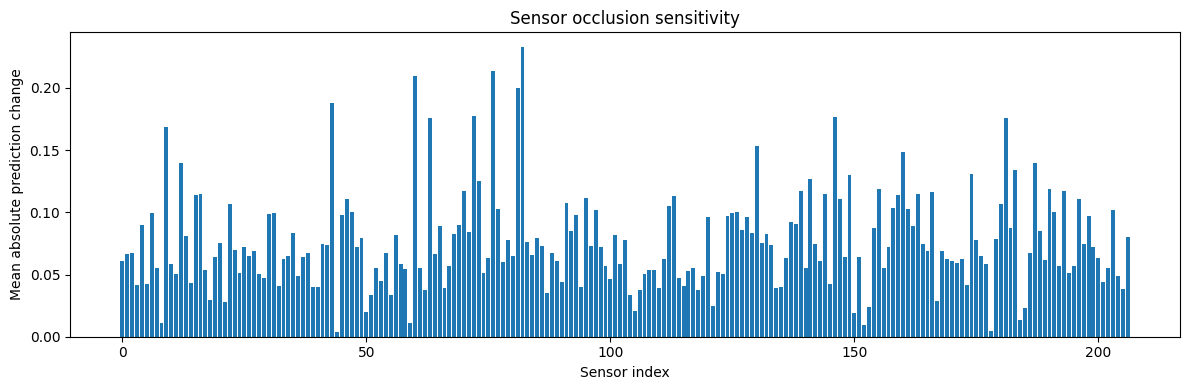

Top 10 sensitive sensors:


,sensor_index,mean_absolute_prediction_change,p95_absolute_prediction_change
82,82,0.233101,1.317758
76,76,0.213465,0.840091
60,60,0.209338,0.887546
81,81,0.199751,1.028663
43,43,0.187908,1.027087
72,72,0.177771,0.893138
146,146,0.176977,1.059700
181,181,0.175758,0.012699
63,63,0.175665,0.752411
9,9,0.168595,0.418473


In [73]:
# Replace a sensor's entire 12-step input history with standardized zero.
sensor_rows = []
for node in range(NUM_NODES):
    X_occ = X_explain.copy()
    X_occ[:, :, node, :] = 0.0
    pred_occ = inverse_scale(predict(X_occ))
    delta = np.abs(pred_occ - baseline_pred_original)
    sensor_rows.append({
        "sensor_index": node,
        "mean_absolute_prediction_change": float(delta.mean()),
        "p95_absolute_prediction_change": float(np.percentile(delta, 95)),
    })

sensor_df = pd.DataFrame(sensor_rows).sort_values("mean_absolute_prediction_change", ascending=False)
display(sensor_df.head(20).round(6))
sensor_df.to_csv(OUTPUT_DIR / "sensor_occlusion_importance.csv", index=False)

plt.figure(figsize=(12, 4))
plt.bar(sensor_df["sensor_index"], sensor_df["mean_absolute_prediction_change"])
plt.xlabel("Sensor index")
plt.ylabel("Mean absolute prediction change")
plt.title("Sensor occlusion sensitivity")
plt.tight_layout()
plt.show()

print("Top 10 sensitive sensors:")
display(sensor_df.head(10))


## 6. Optional input-gradient sensitivity

This computes the gradient of the mean scaled model output with respect to the input traffic values. It is a local sensitivity indicator and can be noisy; interpret alongside the occlusion results rather than as a causal explanation.


,input_step_index,mean_absolute_input_gradient
0,0,6.800000e-07
1,1,1.230000e-06
2,2,2.020000e-06
3,3,2.900000e-06
4,4,3.920000e-06
5,5,4.500000e-06
6,6,5.770000e-06
7,7,6.950000e-06
8,8,9.450000e-06
9,9,1.545000e-05


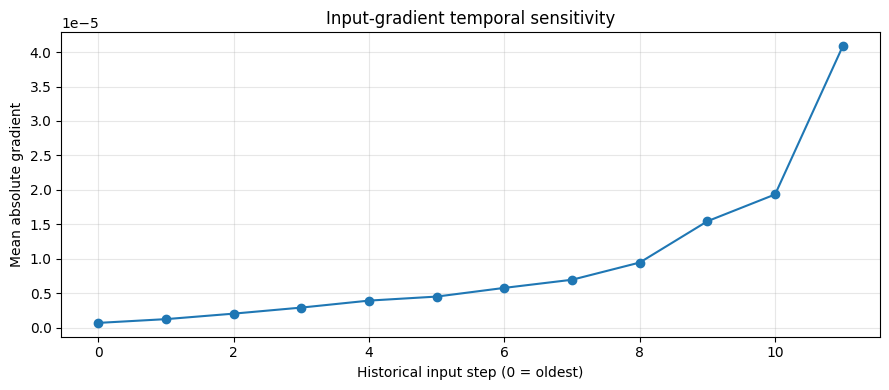

In [74]:
model.eval()
xb = torch.tensor(X_explain[:min(64, len(X_explain))], dtype=torch.float32, device=DEVICE, requires_grad=True)
pred = model(xb, A)
objective = pred.mean()
grad = torch.autograd.grad(objective, xb, retain_graph=False, create_graph=False)[0]
grad_importance = grad.abs().mean(dim=(0, 2, 3)).detach().cpu().numpy()

gradient_df = pd.DataFrame({
    "input_step_index": np.arange(INPUT_STEPS),
    "mean_absolute_input_gradient": grad_importance
})
display(gradient_df.round(8))
gradient_df.to_csv(OUTPUT_DIR / "input_gradient_temporal_sensitivity.csv", index=False)

plt.figure(figsize=(9, 4))
plt.plot(gradient_df["input_step_index"], gradient_df["mean_absolute_input_gradient"], marker="o")
plt.xlabel("Historical input step (0 = oldest)")
plt.ylabel("Mean absolute gradient")
plt.title("Input-gradient temporal sensitivity")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Save run metadata

In [75]:
metadata = {
    "dataset": "METR-LA",
    "checkpoint": str(CHECKPOINT_PATH),
    "input_steps": INPUT_STEPS,
    "output_steps": OUTPUT_STEPS,
    "num_nodes": NUM_NODES,
    "explained_sample_count": int(len(X_explain)),
    "sample_selection_seed": SEED,
    "occlusion_reference": "zero in standardized input space (training mean approximately)",
    "methods": ["temporal occlusion", "sensor occlusion", "input-gradient sensitivity"],
    "caution": "Sensitivity analyses are not causal explanations."
}
with open(OUTPUT_DIR / "explainability_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved explainability outputs under:", OUTPUT_DIR)
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))


Saved explainability outputs under: /content/experiments/explainability
['explainability_metadata.json', 'input_gradient_temporal_sensitivity.csv', 'sensor_occlusion_importance.csv', 'temporal_occlusion_importance.csv']


## Interpretation cautions

- Occlusion scores measure changes relative to a chosen reference input.
- Sensor importance is conditional on the trained model, test subset, graph, and perturbation method.
- These analyses do not establish causality and do not prove that a sensor physically causes congestion.
- If the selected checkpoint was trained with a different implementation, strict checkpoint loading should fail; do not disable strict loading to force it.
